---
title: "L4-10 · Causal machine learning, transport, and fairness"
short_title: "Causal machine learning, transport, and fairness"
subtitle: "Machine learning can estimate a causal quantity only after the quantity is defined and identified; carrying it to a new population, trusting it under shift, or calling a predictor fair each adds assumptions about which mechanisms stay the same and which paths matter."
description: "Define a causal learning target, estimate it with a doubly robust method, and state the extra assumptions that transport, robustness, and fairness claims require."
tags: [level-4, coursebook]
---

(lesson-l4-10)=

:::{div}
:class: qcai-meta
![Level 4 icon](../../_static/icons/qicon-level-4.svg) **Level 4 · Undergraduate** · about 120 minutes  
**Big idea.** Machine learning can estimate a causal quantity only after the quantity is defined and identified; carrying it to a new population, trusting it under shift, or calling a predictor fair each adds assumptions about which mechanisms stay the same and which paths matter.  
**Before this lesson.** [L4-04](#lesson-l4-04), [L4-06](#lesson-l4-06), [L4-08](#lesson-l4-08), [L4-09](#lesson-l4-09), [L3-09](#lesson-l3-09)  
**Lab.** [Confounding and intervention](../../labs/03-causal-inference.ipynb)
:::

## What you will be able to do

- Write a conditional average treatment effect as a learning target, state the assumptions that identify it, and compute plug-in, inverse probability weighted, and doubly robust estimates.
- Use a selection diagram to decide whether stratum effects transport to a target population, and compute the transported effect from the target covariate distribution.
- Explain with a computed example why a predictor that relies on a non-causal feature can fail under a shift, and what invariance across environments does and does not establish.
- Check whether a predictor is counterfactually fair in a stated structural model, and list the modeling assumptions and value choices that the check depends on.

## Why this matters

Three failures with one cause. A flexible model trained on one hospital's records reports that a drug lowers risk by 2 points, and a second hospital with older patients adopts the number. An image classifier that scored well in testing misfires at a new site because it had learned a cue that went with the label only at the training sites [@geirhos2020]. A lender removes a protected attribute from its inputs, yet its scores still differ systematically between groups. In each case a powerful learner answered a question that nobody had posed precisely.

This lesson puts Level 4 to work in machine learning. Learners estimate nuisance functions such as outcome regressions and propensity scores; the causal target and the identification assumptions decide what those estimates mean [@hernan]. Transport theory says when an effect learned in one population carries to another [@pearlbareinboim2014; @bareinboimpearl2016; @bareinboim]. Invariance links causal structure to robustness under distribution shift [@invariant; @scholkopf]. Counterfactual fairness applies the three steps of [L4-09](#lesson-l4-09) to a protected attribute, and its value depends on assumptions and value choices that must be stated in the open.

:::{dropdown} Key terms

**Conditional average treatment effect**
: $\tau(z) = E[Y(1) - Y(0) \mid Z = z]$, the average effect among units with covariates $z$.

**Propensity score**
: $e(z) = P(T = 1 \mid Z = z)$, the probability of treatment given covariates.

**Doubly robust estimator**
: An estimator that is consistent if either the outcome model or the propensity model is correctly specified; AIPW is the standard example.

**Selection diagram**
: A causal graph with extra nodes $S$; an arrow $S \to V$ says the mechanism of $V$ may differ between source and target populations.

**Transport formula**
: $P^*(y \mid do(x)) = \sum_z P(y \mid do(x), z)\,P^*(z)$, valid when the selection nodes point only into the covariates $Z$ and $Z$ blocks their influence on $Y$.

**Invariant prediction**
: Using predictors $S$ for which the conditional law of $Y$ given $X_S$ is the same in every environment; the causal parents of $Y$ have this property when no environment changes the mechanism of $Y$.

**Counterfactual fairness**
: A predictor is counterfactually fair, relative to a structural model, if its distribution for a unit is unchanged when the protected attribute $A$ is set to another value in the unit's counterfactual world.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l4_10 as _lessonfigs

## Define the target, then learn

A causal machine learning project has the same skeleton as any causal analysis. First the target: a population, an intervention, an outcome, a time horizon. Then the assumptions and a graph that justify identification ([L4-04](#lesson-l4-04), [L4-06](#lesson-l4-06)). Only then estimation, where flexible learners help, and finally a check of how sensitive the answer is to the assumptions.

```{mermaid}
graph LR
  T["Define the target"] --> A["Assumptions and graph"]
  A --> I["Identification formula"]
  I --> E["Estimation with learners"]
  E --> S["Sensitivity and limits"]
  S -.-> A
```

*The order of work in causal machine learning. Learners enter only at the estimation step; the dashed arrow says that a sensitivity analysis can send you back to question the assumptions.*

:::{prf:definition} Conditional and average treatment effects
:label: def-l4-10-cate
For a binary treatment $T$ with potential outcomes $Y(1), Y(0)$ and pre-treatment covariates $Z$, the **conditional average treatment effect** is $\tau(z) = E[Y(1) - Y(0) \mid Z = z]$ and the **average treatment effect** is $\mathrm{ATE} = E[\tau(Z)]$. Write $\mu_t(z) = E[Y \mid T = t, Z = z]$ for the outcome regressions and $e(z) = P(T = 1 \mid Z = z)$ for the propensity score.
:::

:::{prf:assumption} Identification assumptions
:label: asm-l4-10-ident
(i) **Consistency**: $Y = Y(T)$. (ii) **Conditional exchangeability**: $Y(t) \perp\!\!\!\perp T \mid Z$ for $t = 0, 1$; in graph terms, $Z$ satisfies the backdoor criterion. (iii) **Positivity**: $0 < e(z) < 1$ for every $z$ with positive probability [@hernan].
:::

:::{prf:proposition} Two identification formulas
:label: prop-l4-10-ident
Under the identification assumptions, $\tau(z) = \mu_1(z) - \mu_0(z)$, and the ATE equals both $E[\mu_1(Z) - \mu_0(Z)]$ and the weighting formula [](#eq-l4-10-ipw).
:::

$$
\mathrm{ATE} = E\left[\frac{T\,Y}{e(Z)} - \frac{(1 - T)\,Y}{1 - e(Z)}\right]
$$ (eq-l4-10-ipw)

:::{prf:proof}
By exchangeability and then consistency, $E[Y(t) \mid Z = z] = E[Y(t) \mid T = t, Z = z] = E[Y \mid T = t, Z = z] = \mu_t(z)$, which needs $P(T = t \mid Z = z) > 0$ (positivity). Subtract and average over $Z$. For the weighting formula, $E[TY/e(Z) \mid Z] = E[T\,Y(1) \mid Z]/e(Z) = e(Z)\,E[Y(1) \mid Z]/e(Z) = E[Y(1) \mid Z]$, using consistency, then exchangeability to factor $E[T\,Y(1) \mid Z] = E[T \mid Z]\,E[Y(1) \mid Z]$. The control term is the same with $1 - T$.
:::

:::{warning} A flexible learner does not create identification
Gradient boosting, random forests, or neural networks can fit $\mu_t$ and $e$ well, and that matters for estimation. None of them can tell you whether $Z$ blocks every backdoor path. If an unmeasured confounder exists, a perfect fit of $\mu_1 - \mu_0$ converges to the wrong number.
:::

## Doubly robust estimation

The plug-in estimator averages $\hat\mu_1(Z_i) - \hat\mu_0(Z_i)$ and is only as good as the outcome model. The inverse probability weighted (IPW) estimator is the sample version of [](#eq-l4-10-ipw) and is only as good as the propensity model. The augmented IPW estimator of Robins, Rotnitzky and Zhao combines them [@robins1994]:

$$
\hat\tau_{\mathrm{AIPW}} = \frac{1}{n}\sum_{i=1}^{n}\left[\hat\mu_1(Z_i) - \hat\mu_0(Z_i) + \frac{T_i\,(Y_i - \hat\mu_1(Z_i))}{\hat e(Z_i)} - \frac{(1 - T_i)(Y_i - \hat\mu_0(Z_i))}{1 - \hat e(Z_i)}\right]
$$ (eq-l4-10-aipw)

:::{prf:proposition} Double robustness
:label: prop-l4-10-dr
Suppose the identification assumptions hold, and let $m_1, m_0, \tilde e$ be fixed functions (the limits of the fitted models) with $0 < \tilde e < 1$. Let $\psi = m_1(Z) - m_0(Z) + T(Y - m_1(Z))/\tilde e(Z) - (1 - T)(Y - m_0(Z))/(1 - \tilde e(Z))$. If either $m_t = \mu_t$ for $t = 0, 1$, or $\tilde e = e$, then $E[\psi] = \mathrm{ATE}$.
:::

:::{prf:proof}
Condition on $Z$. Since $E[T(Y - m_1(Z)) \mid Z] = e(Z)\,(\mu_1(Z) - m_1(Z))$, the treated part of $\psi$ has conditional mean $m_1 + e\,(\mu_1 - m_1)/\tilde e$. If $m_1 = \mu_1$ the correction vanishes and the mean is $\mu_1$. If $\tilde e = e$ the mean is $m_1 + \mu_1 - m_1 = \mu_1$. The control part is the same with $1 - e$ and $1 - \tilde e$. In both cases $E[\psi \mid Z] = \mu_1(Z) - \mu_0(Z)$, and averaging over $Z$ gives the ATE by the identification proposition.
:::


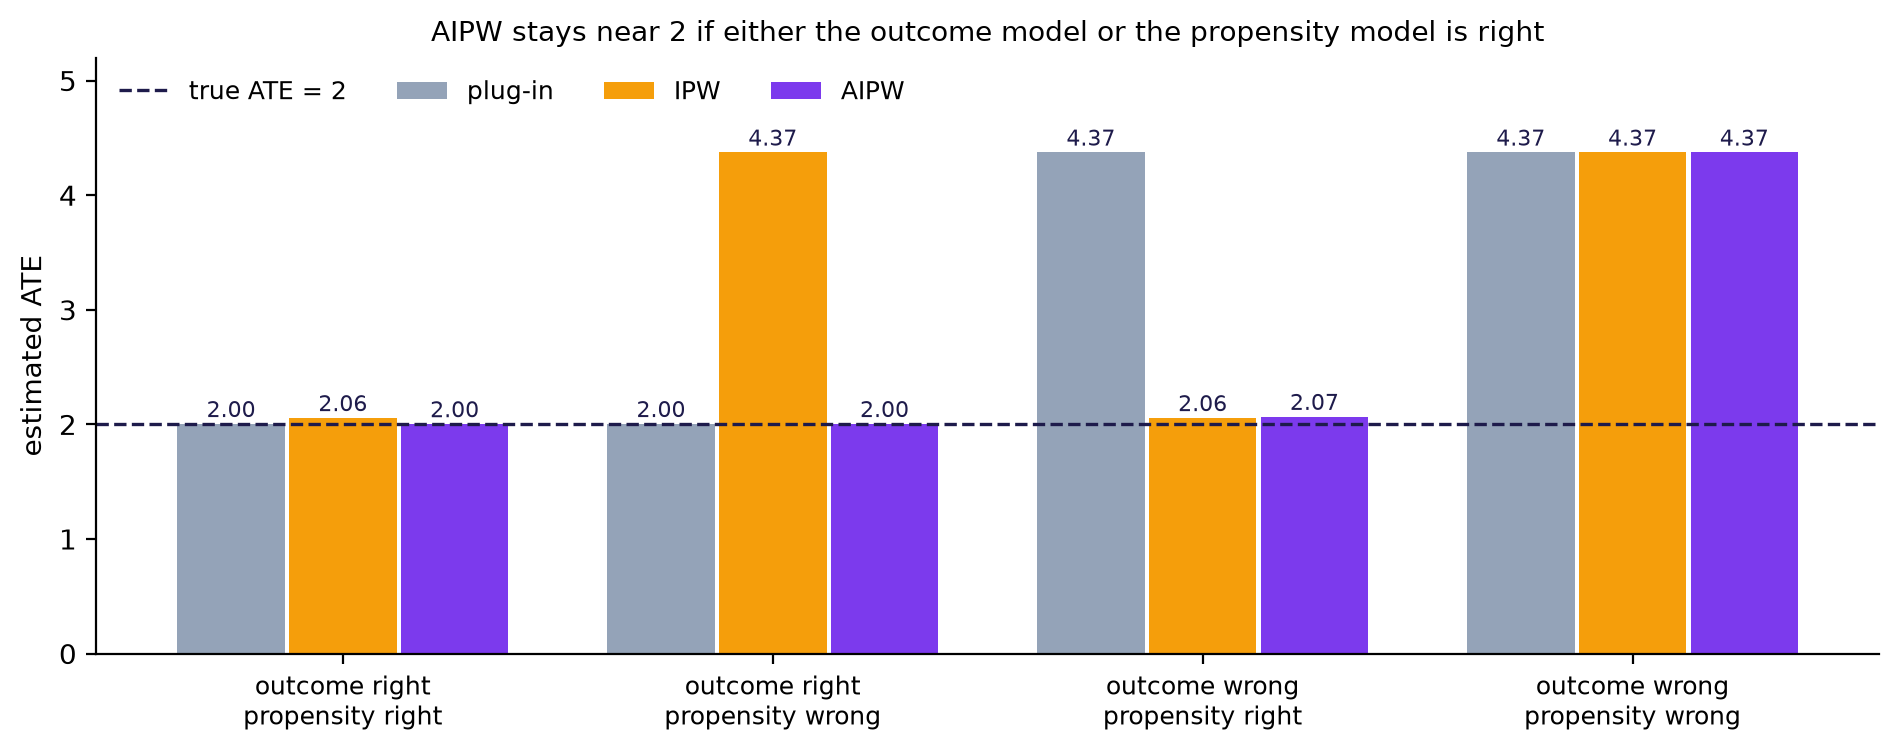

In [2]:
_show_mpl(_lessonfigs.doubly_robust())

*Simulated data with true ATE 2: $Z \sim \mathcal{N}(0, 1)$, $P(T = 1 \mid Z) = 1/(1 + e^{-1.5Z})$, $Y = 2T + Z + 0.5Z^3 + \text{noise}$. A wrong outcome model ignores $Z$; a wrong propensity model is a constant. Plug-in fails when the outcome model is wrong, IPW fails when the propensity model is wrong, and AIPW fails only when both are wrong.*

The simulation behind the figure. Each nuisance model is fitted either correctly or with $Z$ left out; the table shows which estimators survive which mistake. All three estimators collapse to the naive, confounded contrast when both models ignore $Z$.


In [3]:
import numpy as np

def logistic_fit(Z, t, iters=25):
    # Newton's method for a logistic regression of t on the columns of Z
    b = np.zeros(Z.shape[1])
    for _ in range(iters):
        p = 1 / (1 + np.exp(-Z @ b))
        b += np.linalg.solve(Z.T @ (Z * (p * (1 - p))[:, None]), Z.T @ (t - p))
    return 1 / (1 + np.exp(-Z @ b))

def ols_predict(F, y, F_new):
    return F_new @ np.linalg.lstsq(F, y, rcond=None)[0]

rng = np.random.default_rng(3)
n = 20_000
z = rng.normal(0, 1, n)
t = (rng.random(n) < 1 / (1 + np.exp(-1.5 * z))).astype(float)   # confounded treatment
y = 2 * t + z + 0.5 * z ** 3 + rng.normal(0, 1, n)               # true ATE = 2

one = np.ones(n)
props = {'right': logistic_fit(np.column_stack([one, z]), t),     # correct propensity model
         'wrong': np.full(n, t.mean())}                           # ignores Z
outcomes = {}
for name, F in {'right': np.column_stack([one, z, z ** 3]), 'wrong': one[:, None]}.items():
    outcomes[name] = (ols_predict(F[t == 1], y[t == 1], F),       # fitted E[Y | T=1, Z]
                      ols_predict(F[t == 0], y[t == 0], F))       # fitted E[Y | T=0, Z]

print('naive contrast', round(y[t == 1].mean() - y[t == 0].mean(), 3))
for om in ('right', 'wrong'):
    for pm in ('right', 'wrong'):
        m1, m0 = outcomes[om]
        e = props[pm]
        plug = np.mean(m1 - m0)
        ipw = np.mean(t * y / e - (1 - t) * y / (1 - e))
        aipw = np.mean(m1 - m0 + t * (y - m1) / e - (1 - t) * (y - m0) / (1 - e))
        print(f'outcome {om:5s} propensity {pm:5s} | plug-in {plug:6.3f}  IPW {ipw:6.3f}  AIPW {aipw:6.3f}')

naive contrast 4.373
outcome right propensity right | plug-in  2.004  IPW  2.055  AIPW  2.002
outcome right propensity wrong | plug-in  2.004  IPW  4.373  AIPW  2.004
outcome wrong propensity right | plug-in  4.373  IPW  2.055  AIPW  2.066
outcome wrong propensity wrong | plug-in  4.373  IPW  4.373  AIPW  4.373


:::{prf:remark} In practice
Real analyses fit $\hat\mu_t$ and $\hat e$ with flexible learners, usually on separate folds of the data from the ones used to average (cross-fitting [@chernozhukov2018]), and check for propensity scores near 0 or 1, where positivity is in doubt and the weights explode. Libraries such as DoWhy organize the steps of target, graph, identification, estimation, and refutation [@dowhy]. Double robustness protects against one wrong nuisance model, not against a wrong graph.
:::

## Transport to a new population

A study in a source population $\pi$ estimated effects; a decision is needed in a target population $\pi^*$. Write $P$ for the source and $P^*$ for the target. The question is which parts of the causal model are shared [@pearlbareinboim2014; @bareinboim].

:::{prf:definition} Selection diagram
:label: def-l4-10-selection
A **selection diagram** is the causal graph shared by $\pi$ and $\pi^*$, plus selection nodes $S$. An arrow $S \to V$ means the mechanism of $V$ (or the distribution of its background variable) may differ between the two populations. The absence of an arrow from $S$ into $V$ is an assumption: the mechanism of $V$ is the same in both.
:::

```{mermaid}
graph TD
  S["S (population)"] --> Z
  Z --> X
  Z --> Y
  X --> Y
```

*The selection diagram of the running example. The two populations differ only in the distribution of the effect modifier $Z$ (say an age group); the mechanisms of treatment $X$ and outcome $Y$ are shared. An arrow from $S$ into $Y$ would break the transport formula.*

:::{prf:theorem} Transport formula for covariate shift
:label: thm-l4-10-transport
Suppose (a) in the selection diagram, $S$ points only into $Z$, and $Z$ separates $S$ from $Y$ once the arrows into $X$ are removed, that is $Y \perp\!\!\!\perp S \mid Z$ in that graph (this holds in the diagram above); (b) $Z$ is not affected by $X$; (c) $Z$ satisfies the backdoor criterion for $(X, Y)$ in the source; and (d) positivity: $P(x, z) > 0$ in the source for every $z$ with $P^*(z) > 0$. Then [](#eq-l4-10-transport) holds, and for effects $\mathrm{ATE}^* = \sum_z \tau(z)\,P^*(z)$ with $\tau$ estimated in the source [@pearlbareinboim2014; @bareinboim].
:::

$$
P^*(y \mid do(x)) = \sum_z P(y \mid do(x), z)\,P^*(z) = \sum_z P(y \mid x, z)\,P^*(z)
$$ (eq-l4-10-transport)

:::{prf:proof}
In the target, $P^*(y \mid do(x)) = \sum_z P^*(y \mid do(x), z)\,P^*(z \mid do(x))$. By (b), $Z$ is not a descendant of $X$, so $P^*(z \mid do(x)) = P^*(z)$. By (a), $Y \perp\!\!\!\perp S \mid Z$ in the graph with the arrows into $X$ removed, which is the graph of the action $do(x)$, so $P^*(y \mid do(x), z) = P(y \mid do(x), z)$: the stratum-specific causal law is shared. (Pointing only into $Z$ is not enough on its own: if a hidden variable affected both $Z$ and $Y$, conditioning on $Z$ would open the path $S \to Z \leftarrow L \to Y$.) By (c) and (d), $P(y \mid do(x), z) = P(y \mid x, z)$ is estimable from the source in every stratum the target needs.
:::

:::{figure} ../../_static/animations/l4_10_transport.mp4
:alt: A selection diagram with S pointing into Z, two bars for stratum effects 1 and 3, and a row of ten dots that changes from five and five to eight and two; the average effect changes from 2 to 1.4. Then an arrow from S into Y appears and the formula is crossed out.
:width: 100%

Same stratum effects, new weights: $0.5(1) + 0.5(3) = 2$ in the source becomes $0.8(1) + 0.2(3) = 1.4$ in the target. An arrow from $S$ into $Y$ breaks the argument.
:::

:::{dropdown} What the animation shows
The selection diagram shows $Z \to X$, $Z \to Y$, $X \to Y$ and a square node $S$ with an arrow into $Z$, labeled as marking where source and target differ. Bars show the stratum effects $\tau(z)$: 1 for $z = 0$ and 3 for $z = 1$. A row of ten dots shows the source mix, five of each stratum, with $\tau_{\text{source}} = 0.5(1) + 0.5(3) = 2$. The arrow from $S$ flashes, the dots recolor to eight and two (the target mix), and the formula transforms term by term into $\tau_{\text{target}} = 0.8(1) + 0.2(3) = 1.4$. Finally a red arrow from $S$ into $Y$ appears, the formula is crossed out, and a caption says that if $S$ points into $Y$, the stratum effects may differ too.
:::


In [4]:
_show(_lessonfigs.transport_explorer())

**Explore.** Move the slider to change the share of stratum $z = 1$ in the target. The stratum effects stay at 1 and 3; the transported average effect moves along the line $1 + 2p$.

:::{dropdown} What the figure shows
The first panel compares the source mix (0.5 and 0.5, gray) with the target mix ($1 - p$ and $p$, violet) for the two strata, labeled with their effects 1 and 3. The second panel plots the transported ATE $1 + 2p$ against the target share $p$, with a dashed line at the source ATE 2 and a marker at the chosen $p$: 1.4 at $p = 0.2$, 2 at $p = 0.5$, 3 at $p = 1$.
:::

A source study with confounded treatment. Backdoor adjustment within strata recovers $\tau = (1, 3)$; reweighting by the target mix gives 1.4, which matches the target's true effect because the model satisfies the theorem's conditions. The last line breaks condition (a) by changing the mechanism of $Y$ in the target: the formula still says 1.4, but the truth is 2.4.


In [5]:
rng = np.random.default_rng(1)

def population(n, p_z1):
    # Z: effect modifier and confounder; X: treatment; Y := X(1 + 2Z) + Z + noise
    z = rng.random(n) < p_z1
    x = rng.random(n) < np.where(z, 0.7, 0.3)      # treatment depends on Z (confounding)
    y = x * (1 + 2 * z) + z + rng.normal(0, 1, n)
    return z, x, y

def stratum_effects(z, x, y):
    # backdoor adjustment within each stratum of Z
    return np.array([y[(z == k) & x].mean() - y[(z == k) & ~x].mean() for k in (0, 1)])

z, x, y = population(200_000, p_z1=0.5)            # source study
tau = stratum_effects(z, x, y)
print('stratum effects in the source   ', tau.round(3))
print('naive treated-untreated contrast', round(y[x].mean() - y[~x].mean(), 3))
print('source ATE   0.5 tau0 + 0.5 tau1', round(0.5 * tau[0] + 0.5 * tau[1], 3))
w_target = np.array([0.8, 0.2])                     # P*(Z = z), measured in the target
print('transported  0.8 tau0 + 0.2 tau1', round(w_target @ tau, 3))

# compare with the target's true effect, known here because we wrote the model
zt = rng.random(200_000) < 0.2
print('true target ATE                 ', round(np.mean(1 + 2 * zt), 3))
# if the mechanism of Y also differs (S -> Y), the same formula is wrong
print('target ATE when S -> Y adds 1   ', round(np.mean(1 + 2 * zt + 1.0), 3), '(formula still says 1.4)')

stratum effects in the source    [1.002 2.988]
naive treated-untreated contrast 2.791
source ATE   0.5 tau0 + 0.5 tau1 1.995
transported  0.8 tau0 + 0.2 tau1 1.399
true target ATE                  1.4
target ATE when S -> Y adds 1    2.4 (formula still says 1.4)


:::{caution} When transport fails
If $S$ points into $Y$ (the outcome mechanism differs, for example because care differs between hospitals), the source data are compatible with any target effect, and transport needs target outcome data or further assumptions. The same holds if an unmeasured effect modifier is distributed differently, or if the target contains strata never seen in the source, where positivity fails and the formula would extrapolate.
:::

## Shortcuts, shift, and invariance

A predictor can be accurate for the wrong reason. In the model [](#eq-l4-10-shift), $X_c$ is a cause of $Y$ and $X_s$ is an effect of $Y$ whose mechanism depends on the environment $e$. Training happens at $e = 1$.

$$
X_c \sim \mathcal{N}(0, 1), \qquad Y := X_c + N_Y, \qquad X_s := e\,Y + N_s, \qquad N_Y \sim \mathcal{N}(0, 1),\ N_s \sim \mathcal{N}(0, 0.25)
$$ (eq-l4-10-shift)

At $e = 1$, least squares on both features gives $\hat Y = 0.2X_c + 0.8X_s$ with mean squared error 0.2: given $X_c$, $Y$ has variance 1, and $X_s$ is a reading of $Y$ with noise variance 0.25, so the two are weighted 1 to 4 and the error variance is $1/(1 + 4) = 0.2$. The causal predictor $\hat Y = X_c$ has error 1. In a test environment with a new $e$, the error of the all-features predictor is $Y - \hat Y = (0.8 - 0.8e)X_c + (1 - 0.8e)N_Y - 0.8N_s$, so

$$
\mathrm{MSE}(e) = 0.64(1-e)^2 + (1-0.8e)^2 + 0.16
$$ (eq-l4-10-mse)

By [](#eq-l4-10-mse) the error is 0.2 at $e = 1$, 1.8 at $e = 0$, and 5.96 at $e = -1$, while the causal predictor stays at 1 for every $e$. The two are equally good where $1.28e^2 - 2.88e + 0.8 = 0$, at $e \approx 0.32$ and $e \approx 1.93$.

:::{figure} ../../_static/animations/l4_10_spurious_shift.mp4
:alt: A graph X_c to Y to X_s with an environment node e pointing into X_s, and a plot of test error against e: a flat cyan line at 1 and an amber curve that is 0.2 at e = 1 and rises to 5.96 at e = -1.
:width: 100%

The all-features predictor wins in training (0.2 against 1) and loses badly once the environment changes the mechanism of $X_s$; the causal predictor's error does not move.
:::

:::{dropdown} What the animation shows
The diagram shows $X_c \to Y \to X_s$ with a square environment node $e$ pointing into $X_s$, and the mechanism $X_s := e\,Y + N_s$. Two predictors are listed: causal, $\hat Y = X_c$, and all features, $\hat Y = 0.2X_c + 0.8X_s$. On axes of test MSE against $e$ from $-1$ to 2, a dashed line marks training $e = 1$, where the errors are 0.2 and 1. As $e$ sweeps from 1 to $-1$, a cyan dot traces a flat line at 1 and an amber dot traces a rising curve, ending at 5.96 against 1. The formula $\mathrm{MSE}(e) = 0.64(1-e)^2 + (1-0.8e)^2 + 0.16$ appears, and a red dot marks the crossing near $e = 0.32$. A closing line says the causal predictor is worse in training and stable everywhere.
:::


In [6]:
_show(_lessonfigs.shift_explorer())

**Explore.** Move the slider to change the test environment $e$. Left: predictions against the true $Y$ for the causal predictor (cyan) and the all-features predictor (amber); points on the dotted diagonal are perfect. Right: test error of both predictors against $e$.

:::{dropdown} What the figure shows
The first panel plots predictions against the true $Y$ for 160 simulated units. The cyan cloud ($\hat Y = X_c$) never changes. The amber cloud ($0.2X_c + 0.8X_s$) hugs the diagonal at $e = 1$, flattens at $e = 0$, and tilts the wrong way at $e = -1$. The second panel plots the error curves: cyan flat at 1 and amber $0.64(1-e)^2 + (1-0.8e)^2 + 0.16$, with markers at the chosen $e$.
:::

:::{prf:proposition} The causal conditional is invariant
:label: prop-l4-10-invariance
Consider structural models indexed by an environment $e$ that share the mechanism $Y := f(\mathrm{pa}_Y, N_Y)$ and the law of $N_Y$, with $N_Y$ independent of $\mathrm{pa}_Y$ in every environment. Then the conditional law of $Y$ given $\mathrm{pa}_Y = p$ is the same in every environment, whatever the environments do to other mechanisms.
:::

:::{prf:proof}
Given $\mathrm{pa}_Y = p$, $Y = f(p, N_Y)$, and because $N_Y$ is independent of $\mathrm{pa}_Y$, its conditional law given $\mathrm{pa}_Y = p$ is its unconditional law, which does not depend on $e$. So the law of $Y$ given $\mathrm{pa}_Y = p$ is the law of $f(p, N_Y)$ in every environment. Sets that include a child of $Y$, such as $\{X_c, X_s\}$ above, have no such guarantee.
:::

:::{prf:theorem} Coverage of invariant causal prediction
:label: thm-l4-10-icp
For each subset $S$ of predictors, let $H_{0,S}$ be the hypothesis that the conditional law of $Y$ given $X_S$ is the same in all observed environments, and test it at level $\alpha$. Let $\hat S$ be the intersection of all subsets whose hypothesis is not rejected (and $\hat S = \varnothing$ if all are rejected). If the parents $S^* = \mathrm{pa}_Y$ satisfy $H_{0,S^*}$, then $P(\hat S \subseteq S^*) \ge 1 - \alpha$ [@invariant].
:::

:::{prf:proof}
If $H_{0,S^*}$ is not rejected, $S^*$ is one of the sets being intersected, so $\hat S \subseteq S^*$. The test of the true hypothesis $H_{0,S^*}$ rejects with probability at most $\alpha$. Hence $P(\hat S \subseteq S^*) \ge P(H_{0,S^*} \text{ not rejected}) \ge 1 - \alpha$. The guarantee is one-sided: $\hat S$ may be smaller than $S^*$, even empty, when the environments do not vary enough to reject the wrong sets.
:::

A small version of invariant causal prediction with two environments: the first has $\operatorname{sd}(X_c) = 1$ and $e = 1$, the second has $\operatorname{sd}(X_c) = 2$ and $e = -1$. For each subset, fit the regression separately in each environment and test whether the coefficients and the residual variances agree (normal approximations, Bonferroni correction). Only $\{X_c\}$ survives, so the estimate is $\{X_c\}$.


In [7]:
import math
from itertools import combinations

rng = np.random.default_rng(11)

def environment(n, sd_c, e):
    xc = rng.normal(0, sd_c, n)                 # environments shift the cause X_c ...
    y = xc + rng.normal(0, 1, n)                # ... but never the mechanism of Y
    xs = e * y + rng.normal(0, 0.5, n)          # and change the mechanism of the effect X_s
    return np.column_stack([xc, xs]), y

def fit(F, y):
    b = np.linalg.lstsq(F, y, rcond=None)[0]
    r = y - F @ b
    s2 = r @ r / (len(y) - F.shape[1])
    return b, np.sqrt(np.diag(s2 * np.linalg.inv(F.T @ F))), s2

def p_two_sided(zscore):
    return math.erfc(abs(zscore) / math.sqrt(2))

envs = [environment(1000, 1.0, 1.0), environment(1000, 2.0, -1.0)]
names = ['X_c', 'X_s']
accepted = []
for k in range(3):
    for S in combinations(range(2), k):
        (b1, se1, v1), (b2, se2, v2) = [fit(np.column_stack([np.ones(len(yy))] + [X[:, j] for j in S]), yy)
                                        for X, yy in envs]
        ps = [p_two_sided((b1[i] - b2[i]) / math.hypot(se1[i], se2[i])) for i in range(len(b1))]
        ps.append(p_two_sided(math.log(v1 / v2) / math.sqrt(4 / 999)))   # equal residual variance
        p = min(1.0, len(ps) * min(ps))                                   # Bonferroni
        label = '{' + ', '.join(names[j] for j in S) + '}'
        print(label.ljust(12), 'p = %.3g' % p, 'accepted' if p > 0.05 else 'rejected')
        if p > 0.05:
            accepted.append(set(S))
S_hat = set.intersection(*accepted) if accepted else set()
print('ICP estimate of the causal parents:', {names[j] for j in S_hat})

{}           p = 1.13e-41 rejected
{X_c}        p = 1 accepted
{X_s}        p = 0 rejected
{X_c, X_s}   p = 0 rejected
ICP estimate of the causal parents: {'X_c'}


:::{prf:remark} What invariance does not show
Invariance is a consequence of causal structure under the stated assumptions, not a proof of it. Hidden confounding between a parent and $Y$, or an environment that changes the mechanism of $Y$ itself, breaks the guarantee. A causal predictor is also not always the most accurate: in the exercises it loses to the all-features predictor whenever the deployment environments stay close to training. Its virtue is stability under shifts that leave the mechanism of $Y$ alone [@invariant; @scholkopf; @peters].
:::

## Counterfactual fairness

Fairness criteria are formal versions of social goals, and different goals lead to different criteria. Statistical criteria compare groups: equal rates of positive predictions (demographic parity), equal error rates (equalized odds [@hardt2016]), or equal meaning of a score (calibration). When base rates differ between groups, calibration and equal error rates cannot both hold for an imperfect predictor [@kleinberg2016; @chouldechova2017]. Causal criteria ask instead how the protected attribute $A$ influences the prediction through the mechanisms of a model [@bareinboim]. One consequence is general: leaving $A$ out of the inputs does not by itself remove its influence, because $A$ can affect the features that remain.

:::{prf:definition} Counterfactual fairness
:label: def-l4-10-cf-fair
Fix a structural model with protected attribute $A$, features $X$, and background variables $U$, and a predictor $\hat Y = h(X, A)$. Write $\hat Y_{a'}$ for the prediction in the counterfactual world with $A$ set to $a'$. The predictor is **counterfactually fair** if for every $x$ and $a$ with $P(X = x, A = a) > 0$, every $a'$, and every $y$: $P(\hat Y_{a} = y \mid X = x, A = a) = P(\hat Y_{a'} = y \mid X = x, A = a)$. The condition is on the unit's evidence $X = x, A = a$, so it is computed by the three steps of [L4-09](#lesson-l4-09). The definition is due to Kusner, Loftus, Russell and Silva [@kusner2017].
:::

:::{prf:proposition} Predictors of non-descendants are counterfactually fair
:label: prop-l4-10-nondesc
If $\hat Y$ is a function only of $U$ and of variables that are not descendants of $A$ in the model, then $\hat Y$ is counterfactually fair [@kusner2017].
:::

:::{prf:proof}
Setting $A$ to $a'$ changes only the mechanisms downstream of $A$. A variable that is not a descendant of $A$ is computed from $U$ by mechanisms that never read $A$, so its value in the counterfactual world equals its factual value for every $u$. Hence $\hat Y_{a}(u) = \hat Y_{a'}(u)$ for every $u$, and the two conditional distributions in the definition are equal.
:::

The running example is as small as possible: one feature with $X := U + A$, where $U$ is independent of $A$. Consider $h_1 = X$, which does not take $A$ as input, and $h_2 = X - A$, which does. A unit with $A = 1$ and $X = 3$ has $u = 3 - 1 = 2$ by abduction. In the world with $A$ set to 0, $X = 2 + 0 = 2$. So $h_1$ gives 3 and 2: it is not counterfactually fair even though it never sees $A$. And $h_2 = X - A$ gives 2 and 2 for every unit, because in this model $h_2 = U$, a non-descendant of $A$.

:::{figure} ../../_static/animations/l4_10_fairness.mp4
:alt: Two copies of a small graph, A and U pointing into X, share the node U. In the unit's own world A = 1 and X = 3; in the world with A set to 0, X = 2. A predictor equal to X gives 3 and 2; a predictor equal to X - A gives 2 and 2.
:width: 100%

One unit, two worlds, in the model $X := U + A$: the predictor that ignores $A$ changes when $A$ changes, and the predictor $h_2 = X - A$ does not.
:::

:::{dropdown} What the animation shows
The model $X := U + A$, with $U$ independent of $A$, is written at the top. A shared node $U$ sits between two copies of the graph $A \to X \leftarrow U$. In the unit's own world, $A = 1$ and $X = 3$, and abduction writes $u = 3 - 1 = 2$ beside $U$. In the world with $A$ set to 0, the label $A := 0$ appears and $X = 2 + 0 = 2$. Below, $h_1 = X$ gives 3 versus 2, marked as changing and not counterfactually fair. Then $h_2 = X - A$ gives 2 versus 2, marked as the same in both worlds, in this model, and boxed. A closing line says the verdict depends on the model and on choosing to block the path from $A$ to $X$.
:::

The same check by computer: abduction for the unit, then each predictor in both worlds, then a population of units drawn from the model.


In [8]:
# Counterfactual fairness in the model X := U + A, with U independent of A
def feature(u, a):
    return u + a

h1 = lambda x, a: x                             # does not take A as input
h2 = lambda x, a: x - a                         # uses A to undo its effect on X

a_obs, x_obs = 1, 3
u = x_obs - a_obs                               # abduction
for name, h in (('h1 = X    ', h1), ('h2 = X - A', h2)):
    own, other = h(feature(u, a_obs), a_obs), h(feature(u, 0), 0)
    print(name, '| own world', own, '| world with A set to 0', other)

# the same check for many units drawn from the model
rng = np.random.default_rng(5)
U = rng.normal(0, 1, 10_000)
A = rng.integers(0, 2, 10_000)
for name, h in (('h1', h1), ('h2', h2)):
    gap = np.abs(h(feature(U, 1), 1) - h(feature(U, 0), 0)).max()
    print(name, 'largest change when A is flipped:', round(gap, 6))
print('h2 recovers U for every unit:', np.allclose(h2(feature(U, A), A), U))

h1 = X     | own world 3 | world with A set to 0 2
h2 = X - A | own world 2 | world with A set to 0 2
h1 largest change when A is flipped: 1.0
h2 largest change when A is flipped: 0.0
h2 recovers U for every unit: True


:::{important} What this check does and does not establish
The verdict on $h_2$ is relative to the model. It assumes that $X := U + A$ is the right mechanism, with an effect of exactly 1 and no other path from $A$, and that $U$ is independent of $A$; neither can be fully checked from data. Treating the whole path $A \to X$ as one that the prediction should not follow is a value judgment; path-specific criteria allow some paths and block others. What it means to set a protected attribute to another value is itself debated, so the counterfactual world needs a careful definition in each application. Counterfactual fairness can conflict with statistical criteria and with accuracy, and a fair predictor does not by itself make the decisions built on it fair. These choices belong to the people affected and accountable, not to the algorithm.
:::

## Worked example

:::{admonition} Transporting an effect across three strata
:class: tip

A trial in a source population estimated stratum effects $\tau = (0.5, 1.5, 4)$ for three age groups, whose shares in the source were $(0.2, 0.5, 0.3)$. A target population has shares $(0.5, 0.4, 0.1)$. The age groups are the only known difference between the populations. Estimate the target ATE and say what must be true for the estimate to be valid.

1. Source ATE, as a check: $0.2(0.5) + 0.5(1.5) + 0.3(4) = 0.1 + 0.75 + 1.2 = 2.05$.
2. Selection diagram: $S \to Z$ only, with $Z$ the age group, pre-treatment and unaffected by treatment. The trial randomized treatment, so $Z$ satisfies the backdoor criterion trivially, and each age group appears in the source with both arms (positivity).
3. Transport by [](#eq-l4-10-transport): $\mathrm{ATE}^* = 0.5(0.5) + 0.4(1.5) + 0.1(4) = 0.25 + 0.6 + 0.4 = 1.25$.
4. Validity: the stratum effects must be the same in the target (no $S \to Y$ and no unmeasured effect modifier distributed differently). If the target also had a fourth age group absent from the source, its effect would be unidentified from these data.

**Result.** $\mathrm{ATE}^* = 1.25$ against a source ATE of $2.05$: the target has more people in the group with the smallest effect. The number is only as good as the assumption that the age groups carry all the relevant differences.
:::

## Exercises

**1. (Core)** Conditional effects in two strata are 2 and $-1$. Target weights are 0.25 and 0.75. Calculate the transported average effect under the stability assumptions of the transport theorem. Does that number establish that a policy based on it is fair?

:::{dropdown} Solution
$0.25(2) + 0.75(-1) = -0.25$. This is a target-population causal average under the assumptions. It does not establish fairness, which needs a stated criterion, a model of how the protected attribute acts, and further justification.
:::

**2. (Core)** Four units have (treatment, outcome, propensity) equal to $(1, 4, 0.8)$, $(1, 2, 0.5)$, $(0, 1, 0.5)$, $(0, 3, 0.2)$. Compute the IPW estimate $\frac{1}{n}\sum_i [T_iY_i/e_i - (1 - T_i)Y_i/(1 - e_i)]$.

:::{dropdown} Solution
Treated terms: $4/0.8 = 5$ and $2/0.5 = 4$. Control terms: $1/0.5 = 2$ and $3/(1 - 0.2) = 3.75$. The estimate is $(5 + 4 - 2 - 3.75)/4 = 3.25/4 = 0.8125$.
:::

**3. (Stretch)** Show that the AIPW estimator [](#eq-l4-10-aipw) equals the IPW estimator when $\hat\mu_0 = \hat\mu_1 = 0$, and equals the plug-in estimator when every residual $Y_i - \hat\mu_{T_i}(Z_i)$ is zero.

:::{dropdown} Solution
With $\hat\mu_t = 0$ the bracket is $T_iY_i/\hat e(Z_i) - (1 - T_i)Y_i/(1 - \hat e(Z_i))$, the IPW summand. If every residual is zero, then for a treated unit $Y_i - \hat\mu_1(Z_i) = 0$ and the term $(1 - T_i)(\dots)$ is zero, and for a control unit $Y_i - \hat\mu_0(Z_i) = 0$ and $T_i(\dots) = 0$; both correction terms vanish and the bracket is $\hat\mu_1(Z_i) - \hat\mu_0(Z_i)$, the plug-in summand.
:::

**4. (Stretch)** In the shift model [](#eq-l4-10-shift), compute $\mathrm{MSE}(e)$ for the all-features predictor at $e = 0.5$, $e = 1.5$, and $e = 2$. If deployment environments are known to lie in $[0.5, 1.5]$, which predictor has the smaller worst-case error?

:::{dropdown} Solution
From [](#eq-l4-10-mse): $\mathrm{MSE}(0.5) = 0.64(0.25) + 0.6^2 + 0.16 = 0.16 + 0.36 + 0.16 = 0.68$; $\mathrm{MSE}(1.5) = 0.64(0.25) + 0.2^2 + 0.16 = 0.36$; $\mathrm{MSE}(2) = 0.64 + 0.36 + 0.16 = 1.16$. The function is a convex quadratic in $e$, so on $[0.5, 1.5]$ its maximum is at an endpoint, $0.68 < 1$. The all-features predictor is better throughout that range; the causal predictor is preferable when the shift can be large or is unknown.
:::

**5. (Challenge)** Take the model $X_1 := U + A$, $X_2 := U + N$ with $U$, $N$, $A$ independent, and the linear predictor $\hat Y = w_1X_1 + w_2X_2 + w_3A$. (a) For which weights is $\hat Y$ counterfactually fair? (b) Is the predictor $X_1$, which leaves out $A$, counterfactually fair? (c) Does $h = X_1 - A$ also satisfy demographic parity, $\hat Y \perp\!\!\!\perp A$, in this model?

:::{dropdown} Solution
(a) Abduction fixes $u$ and $n$. Setting $A$ from $a$ to $a'$ changes $X_1$ by $a' - a$ and leaves $X_2$ unchanged, so $\hat Y_{a'} - \hat Y_{a} = (w_1 + w_3)(a' - a)$. The predictor is counterfactually fair exactly when $w_3 = -w_1$, for any $w_2$. (b) No: $w_1 = 1$, $w_3 = 0$, and the prediction changes by $a' - a$. (c) Yes: $X_1 - A = U$, which is independent of $A$. In this model the two criteria agree for $h$; in other models, for example if $U$ depended on $A$, they need not.
:::

**6. (Challenge)** Show that when the selection diagram has an arrow $S \to Y$, the source distribution cannot determine $\mathrm{ATE}^*$: for the running transport example, construct a family of target models that all agree with the source data and with $P^*(z) = (0.8, 0.2)$ but have different target effects.

:::{dropdown} Solution
Let the source model be $Y := X(1 + 2Z) + Z + N_Y$ and the target model $Y := X(1 + 2Z + \delta) + Z + N_Y$ for any real $\delta$, with the same mechanism for $X$ given $Z$ and $P^*(Z = 1) = 0.2$. The source data are generated by the first model whatever $\delta$ is, and the target covariate distribution is the same for all $\delta$. The target effect is $\mathrm{ATE}^* = 0.8(1 + \delta) + 0.2(3 + \delta) = 1.4 + \delta$, which takes every real value. So no function of the source distribution and $P^*(z)$ can equal $\mathrm{ATE}^*$ for all these models.
:::

## Check your understanding

**1. What must come before fitting a causal effect learner?**

- **A.** The most flexible model available
- **B.** A guarantee that all populations share one effect
- **C.** A decision to remove every demographic variable
- **D.** A defined causal target and justified identification assumptions

:::{dropdown} Show the answer
**D. A defined causal target and justified identification assumptions**

A learner estimates quantities inside a causal analysis. The target and the identification assumptions decide whether its estimates answer the intended causal question.
:::

**2. Stratum effects are 1 and 3. The target population has stratum shares 0.8 and 0.2, and the selection diagram has an arrow from $S$ into the stratum variable only. What is the transported ATE?**

- **A.** It cannot be computed
- **B.** 2
- **C.** 2.6
- **D.** 1.4

:::{dropdown} Show the answer
**D. 1.4**

With the selection node pointing only into $Z$, the stratum effects are shared, so $\mathrm{ATE}^* = 0.8(1) + 0.2(3) = 1.4$. The value 2 uses the source shares and 2.6 swaps the weights.
:::

**3. In the model $X := U + A$ with $U$ independent of $A$, is the predictor $h_1 = X$, which does not take $A$ as input, counterfactually fair?**

- **A.** It depends only on the accuracy of the predictor
- **B.** Yes, because U is independent of A
- **C.** No, because setting A to another value changes X and therefore the prediction
- **D.** Yes, because the predictor never reads A

:::{dropdown} Show the answer
**C. No, because setting A to another value changes X and therefore the prediction**

For a unit with $A = 1$, $X = 3$, abduction gives $u = 2$; with $A$ set to 0, $X = 2$, so the prediction moves from 3 to 2. Leaving $A$ out of the inputs does not block its effect through $X$.
:::

**4. In a graph where $Z$ satisfies the backdoor criterion for the effect of $X$ on $Y$, which expression equals $P(y \mid do(x))$?** *(Review of [L4-04](#lesson-l4-04))*

- **A.** $\sum_z P(y \mid x, z)\,P(z \mid x)$
- **B.** $P(y \mid x)$
- **C.** $\sum_z P(y \mid z)\,P(z \mid x)$
- **D.** $\sum_z P(y \mid x, z)\,P(z)$

:::{dropdown} Show the answer
**D. $\sum_z P(y \mid x, z)\,P(z)$**

Backdoor adjustment averages the stratum-specific outcome risks over the marginal distribution of $Z$. Weighting by $P(z \mid x)$ instead just rebuilds the observational $P(y \mid x)$. The transport formula has the same shape, with the target's $P^*(z)$.
:::

## Common misconceptions

- **"A more accurate model gives a more causal answer."** Accuracy measures how well a model fits the observed distribution. Without identification assumptions, a perfect fit of outcome regressions can converge to a confounded contrast, as the naive contrast of 4.37 against a true effect of 2 shows in the simulation.
- **"Removing the protected attribute from the inputs makes a model fair."** Other features can carry the attribute's influence. In the model $X := U + A$, the predictor $X$ never reads $A$ yet changes when $A$ changes; whether that is acceptable is a value judgment that must be made explicitly.
- **"The causal predictor is always the most accurate one."** In the training environment the causal predictor had error 1 against 0.2 for the predictor that used an effect of $Y$. Its advantage is stability when environments change mechanisms other than that of $Y$.
- **"An effect estimated well in one population applies everywhere."** Transport needs a selection diagram in which the populations differ only in measured covariates that block the selection nodes from $Y$, plus source data in every target stratum. A changed outcome mechanism defeats reweighting.

:::{caution} Scope and limits
The simulations in this lesson are illustrations with known models; they show how the methods behave when their assumptions hold or fail, not that the assumptions hold in any real application. The transport theorem is stated for the simple case of covariate shift with a backdoor set; the general theory of transportability handles more complex selection diagrams and is not covered. The invariance demonstration uses normal approximations, two environments, and a Bonferroni correction; the published method has more careful tests and confidence statements. Counterfactual fairness is one criterion among several, it is relative to an assumed structural model, and the fairness example is deliberately abstract. Nothing here settles which fairness criterion is appropriate in a given setting.
:::

:::{seealso} Where this leads
The same discipline (define the target, state the assumptions, then estimate) carries into the rest of the course. Level 6 builds causal models for quantum systems, where the questions of intervention, invariance, and transport have to be asked again for quantum mechanisms, and Level 7 reads claims about quantum machine learning with the same accounting of assumptions used here.
:::

:::{dropdown} For instructors

**Why this lesson.** Students arrive with machine learning habits (fit, validate, deploy) and need to see where causal assumptions enter that pipeline. The lesson connects the identification results of Level 4 to estimators used in practice, to transport across populations, to robustness under shift, and to fairness, while insisting that each claim names its assumptions [@hernan; @bareinboim; @invariant; @scholkopf].

**Teaching notes.**

- Start with the doubly robust figure: ask students to predict which estimator fails in each of the four settings before revealing the bars, then derive the proof of double robustness on the board.
- Have students draw the selection diagram before computing any transported number; ask what would have to be true for an arrow into $Y$ to be absent.
- In the shift example, emphasize that the all-features predictor is the better choice near training; the point is not that causal models always win, but what kind of shift each predictor tolerates.
- Discuss counterfactual fairness neutrally: present the model, the computation, and then the list of assumptions and value choices, and let students argue about which choices a given application needs.

**Assessment.** The stretch exercises check the estimator algebra and the shift computation; the challenge exercises test whether students can derive a fairness condition in a model and construct a non-transportability argument. The check questions cover the target-first principle, the transport formula, and the limits of removing an attribute.

**Going further.** Implement cross-fitted AIPW with a flexible learner and compare its confidence interval with that of the plug-in estimator. Read the discussion of invariance and causal representation learning in Schölkopf and coauthors [@scholkopf], and the chapters on transportability and fairness in Bareinboim's roadmap [@bareinboim].

:::

## References

This lesson draws on [@hernan; @bareinboim; @pearl; @invariant; @scholkopf; @peters; @dowhy; @geirhos2020; @pearlbareinboim2014; @bareinboimpearl2016; @robins1994; @chernozhukov2018; @hardt2016; @kleinberg2016; @chouldechova2017; @kusner2017].

**Further reading.**

- [@invariant]: The original invariant causal prediction paper, with tests, confidence statements, and identifiability results.
- [@bareinboim]: Covers selection diagrams and transportability in general, and causal approaches to fairness.
- [@dowhy]: A Python library that structures an analysis as model, identify, estimate, and refute.

**Next:** [L5-01 · States and the Born rule](#lesson-l5-01)
